In [209]:
!pip install captum   

In [210]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
import torchvision.models as models
import cv2



import captum
from captum.attr import IntegratedGradients, Occlusion, LayerGradCam, LayerAttribution
from captum.attr import visualization as viz

import os, sys
import json

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

In [211]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)


cuda


In [212]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 3)
model.load_state_dict(torch.load("/home/dbtproject/barsha/np_code_new/checkpoints_old/best_weights_cv.pth", map_location=device))
model.to(device)
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [213]:
# model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
# model = model.eval()

(2560, 1920)


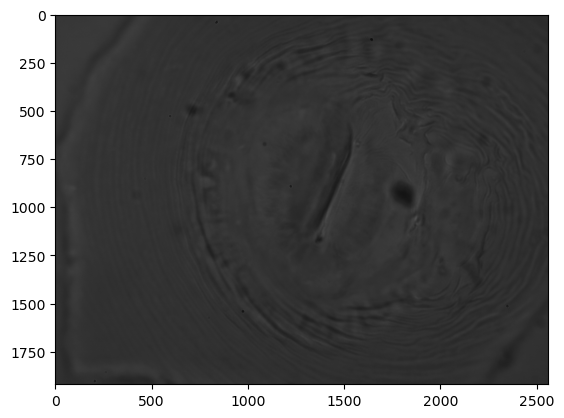

In [214]:
# test_img = Image.open('/home/dbtproject/barsha/Image/test_set/Class1_Incognita/Meloidogyne incognita_13.jpeg')
# test_img_data = np.asarray(test_img)
# plt.imshow(test_img_data)
# plt.show()

def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB') 
        
test_img = get_image('/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_12_PP_2.tiff')
plt.imshow(test_img)
print(test_img.size)

In [215]:
# model expects 224x224 3-color image
transform = transforms.Compose([
 transforms.Resize(232),
 transforms.CenterCrop(224),
 transforms.ToTensor()
])

#standard ImageNet normalization
transform_normalize = transforms.Normalize(
     mean=[0.485, 0.456, 0.406],
     std=[0.229, 0.224, 0.225]
 )

transformed_img = transform(test_img)
input_img = transform_normalize(transformed_img)
input_img = input_img.unsqueeze(0).to(device) # the model requires a dummy batch dimension
print(input_img)



tensor([[[[-1.2788, -1.3130, -1.3302,  ..., -1.2959, -1.2959, -1.3130],
          [-1.3130, -1.3473, -1.3473,  ..., -1.2788, -1.2788, -1.2959],
          [-1.3302, -1.3473, -1.3473,  ..., -1.2788, -1.2788, -1.2788],
          ...,
          [-1.2617, -1.2617, -1.2617,  ..., -1.2617, -1.2617, -1.2617],
          [-1.3130, -1.3302, -1.3302,  ..., -1.2617, -1.2788, -1.2788],
          [-1.3987, -1.3987, -1.3815,  ..., -1.2617, -1.2617, -1.2617]],

         [[-1.1779, -1.2129, -1.2304,  ..., -1.1954, -1.1954, -1.2129],
          [-1.2129, -1.2479, -1.2479,  ..., -1.1779, -1.1779, -1.1954],
          [-1.2304, -1.2479, -1.2479,  ..., -1.1779, -1.1779, -1.1779],
          ...,
          [-1.1604, -1.1604, -1.1604,  ..., -1.1604, -1.1604, -1.1604],
          [-1.2129, -1.2304, -1.2304,  ..., -1.1604, -1.1779, -1.1779],
          [-1.3004, -1.3004, -1.2829,  ..., -1.1604, -1.1604, -1.1604]],

         [[-0.9504, -0.9853, -1.0027,  ..., -0.9678, -0.9678, -0.9853],
          [-0.9853, -1.0201, -

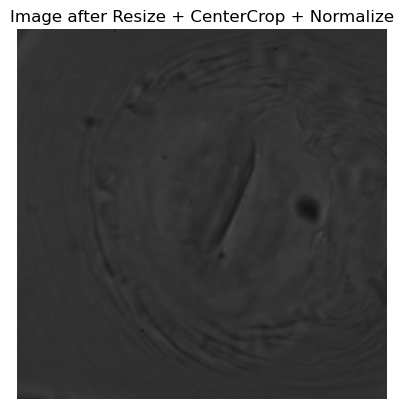

In [216]:
tensor_img = input_img.squeeze(0).cpu()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

tensor_img = tensor_img * std + mean

img_np = tensor_img.permute(1, 2, 0).numpy()
img_np = np.clip(img_np, 0, 1)

plt.imshow(img_np)
plt.axis("off")
plt.title("Image after Resize + CenterCrop + Normalize")
plt.show()

In [217]:
print(input_img.shape)   # should be [1, 3, H, W]

torch.Size([1, 3, 224, 224])


In [218]:
baseline = torch.zeros_like(input_img).to(device)


In [219]:
class_names = [
    "Meloidogyne graminicola",
    "Meloidogyne incognita",
    "Meloidogyne javanica"
]


In [220]:
output = model(input_img)
# output = F.softmax(output, dim=1)
pred_class = output.argmax(dim=1).item()
print("Predicted class:", class_names[pred_class])
score = output[0, pred_class].item()
# confidence = max(pred_class)
print('prediction Score:',score)


Predicted class: Meloidogyne graminicola
prediction Score: 0.5754191279411316


In [221]:
import torch.nn.functional as F

output = model(input_img)

# Convert logits → probabilities
probs = F.softmax(output, dim=1)

pred_class = probs.argmax(dim=1).item()
confidence = probs[0, pred_class].item()

print("Predicted class:", class_names[pred_class])
print("Confidence:", confidence)


Predicted class: Meloidogyne graminicola
Confidence: 0.6071130037307739


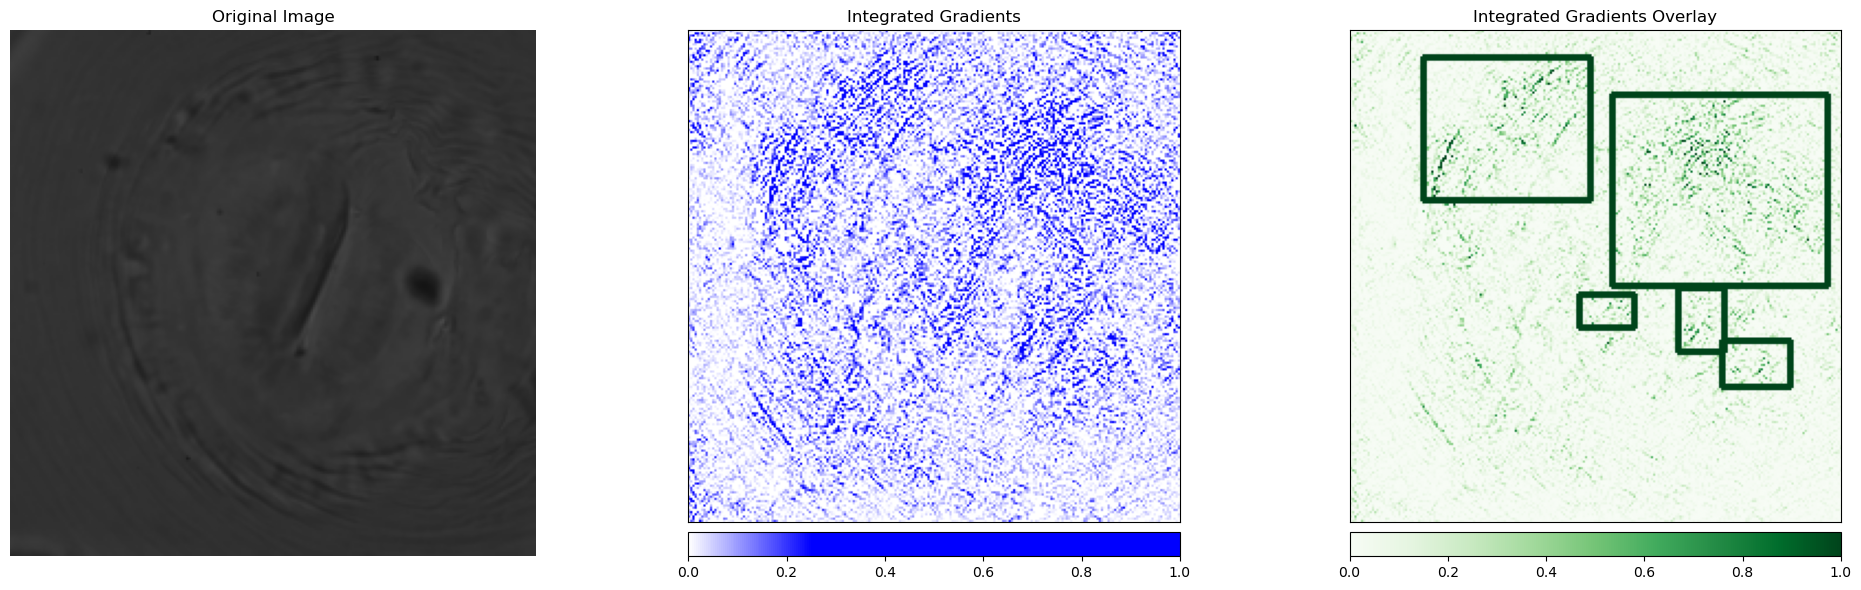

In [222]:
#feature attribution with IG
integrated_gradients = IntegratedGradients(model)

# Ask the algorithm to attribute our output target to
attributions_ig = integrated_gradients.attribute(input_img, target=pred_class, n_steps=200)


img = transformed_img.squeeze().cpu().numpy()
img = np.transpose(img, (1,2,0))
# attr = attributions_ig.squeeze().cpu().detach().numpy()
# attr = np.transpose(attr, (1, 2, 0))

# img = transformed_img.squeeze().cpu().detach().numpy()
# img = np.transpose(img, (1, 2, 0))
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Show the original image for comparison
# plt.figure(figsize=(6,6))
axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis("off")


default_cmap = LinearSegmentedColormap.from_list('custom blue',
                                                 [(0, '#ffffff'),
                                                  (0.25, '#0000ff'),
                                                  (1, '#0000ff')], N=256)

_ = viz.visualize_image_attr(np.transpose(attributions_ig.squeeze().cpu().detach().numpy(), (1,2,0)),
                             np.transpose(transformed_img.squeeze().cpu().detach().numpy(), (1,2,0)),
                             method='heat_map',
                             cmap=default_cmap,
                             show_colorbar=True,
                             sign='positive',
                             plt_fig_axis=(fig, axes[1]),
                             title='Integrated Gradients',
                             use_pyplot=False)

# ---- IG attribution map ----
# attr = attributions_ig.squeeze().cpu().detach().numpy()
# attr = np.transpose(attr, (1, 2, 0))
# img_np = img.copy()   # already H×W×3

# # ---- Original image ----
# axes[2].imshow(img_np)
# axes[2].axis("off")

# _ = viz.visualize_image_attr(
#     attr,
#     img_np,
#     method='blended_heat_map',   # ✅ FIX
#     sign='positive',
#     cmap=default_cmap,
#     alpha_overlay=0.6,
#     show_colorbar=True,
#     plt_fig_axis=(fig, axes[2]),
#     title="Integrated Gradients Overlay",
#     use_pyplot=False
# )



__ =viz.visualize_image_attr(
    np.transpose(attributions_ig.squeeze().cpu().detach().numpy(), (1,2,0)),
    img,
    method='heat_map',
    sign='positive',
    show_colorbar=True,
    alpha_overlay=0.6,
    plt_fig_axis=(fig, axes[2]),
    title='Integrated Gradients Overlay',
    use_pyplot=False
)



attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

ig_map = np.abs(attr).sum(axis=2)
ig_map = (ig_map - ig_map.min()) / (ig_map.max() - ig_map.min() + 1e-8)


threshold = np.percentile(ig_map, 98)  # top 2% IG values
binary_mask = (ig_map >= threshold).astype(np.uint8)

kernel = np.ones((9, 9), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_mask,
    connectivity=8
)


overlay_img = axes[2].images[-1].get_array().copy()
overlay_img = (overlay_img * 255).astype(np.uint8)


for i in range(1, num_labels):  # skip background
    x, y, w, h, area = stats[i]

    if area < 150:  # remove tiny noisy boxes
        continue

    cv2.rectangle(
        overlay_img,
        (x, y),
        (x + w, y + h),
        (255, 0, 0), 
        2
    )

axes[2].images[-1].set_data(overlay_img / 255.0)
plt.draw()

plt.tight_layout()
plt.show()


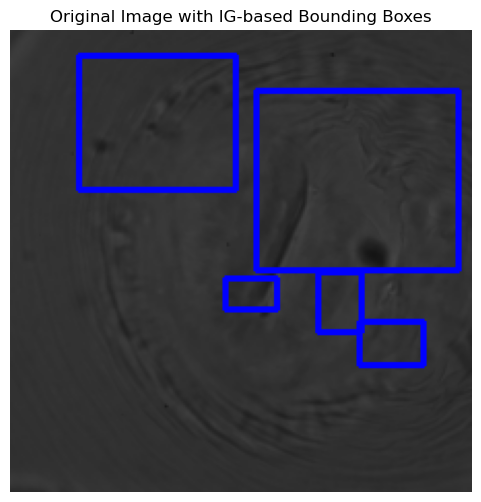

In [223]:


# 1. Integrated Gradients 

integrated_gradients = IntegratedGradients(model)
attributions_ig = integrated_gradients.attribute(
    input_img, target=pred_class, n_steps=200
)


# 2. Prepare ORIGINAL image

img = transformed_img.squeeze().cpu().numpy()
img = np.transpose(img, (1, 2, 0))

# normalize for display
# img_disp = (img - img.min()) / (img.max() - img.min() + 1e-8)
img_new = (img * 255).astype(np.uint8)

# 3. Build IG importance map

attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

ig_map = np.abs(attr).sum(axis=2)
ig_map = (ig_map - ig_map.min()) / (ig_map.max() - ig_map.min() + 1e-8)

# 4. Select important IG regions (ROBUST)

threshold = np.percentile(ig_map, 98)   # top 2%
binary_mask = (ig_map >= threshold).astype(np.uint8)

# merge nearby pixels
kernel = np.ones((9, 9), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

# 5. Connected components → boxes

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_mask, connectivity=8
)

boxed_img = img_new.copy()

for i in range(1, num_labels):  # skip background
    x, y, w, h, area = stats[i]

    if area < 150:   # remove tiny noise
        continue

    cv2.rectangle(
        boxed_img,
        (x, y),
        (x + w, y + h),
        (0, 0, 255),   #blue box
        2
    )

# FINAL result (ONLY ORIGINAL IMAGE)
plt.figure(figsize=(6, 6))
plt.imshow(boxed_img)
plt.axis("off")
plt.title("Original Image with IG-based Bounding Boxes")
plt.show()


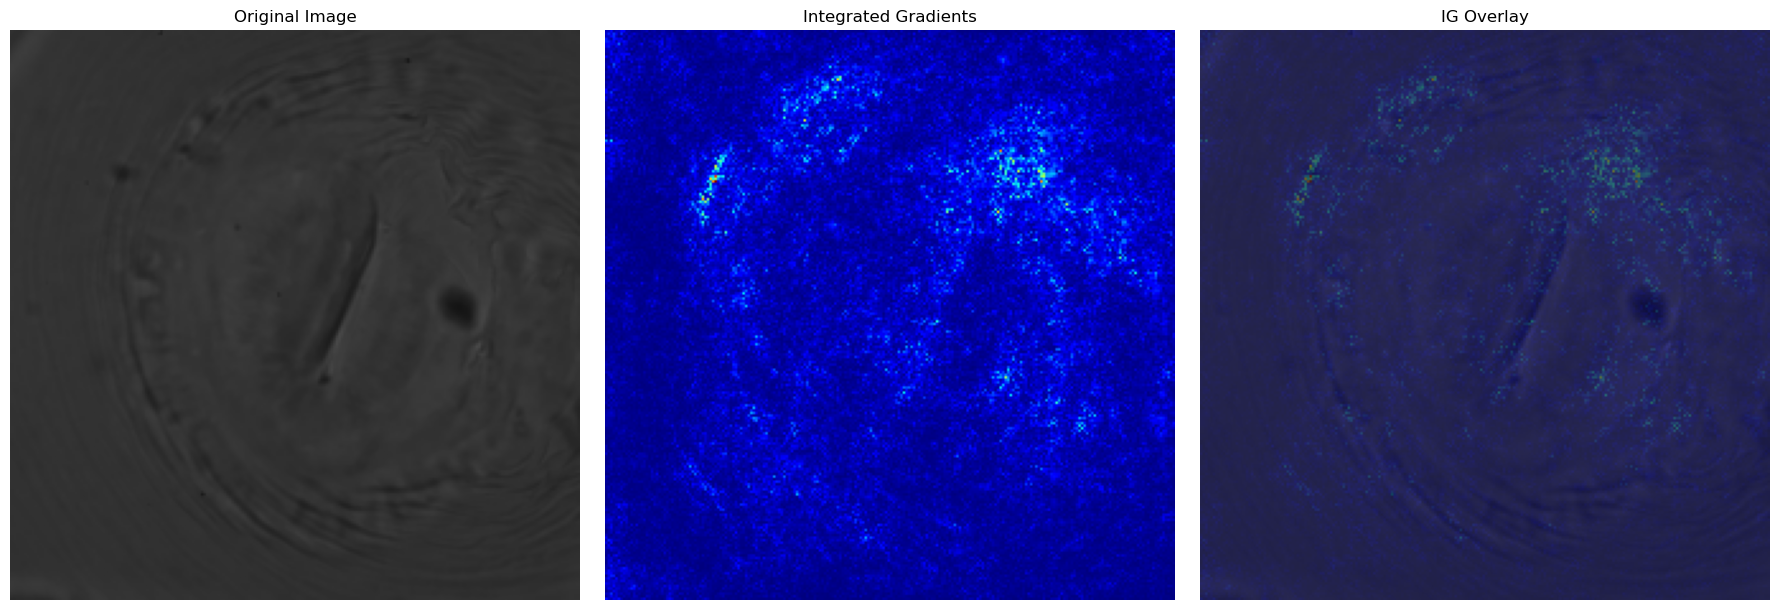

In [224]:
img = transformed_img.squeeze().cpu().numpy()
img = np.transpose(img, (1, 2, 0))


attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

# Convert to single channel importance map
attr = np.abs(attr).sum(axis=2)

# Normalize IG
attr = (attr - attr.min()) / (attr.max() - attr.min() + 1e-8)



heatmap = cv2.applyColorMap(
    np.uint8(255 * attr),
    cv2.COLORMAP_JET
)

heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
heatmap = heatmap / 255.0

alpha = 0.3  # controls visibility
ig_overlay = (1 - alpha) * img + alpha * heatmap

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].imshow(img)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(attr, cmap="jet")
axes[1].set_title("Integrated Gradients")
axes[1].axis("off")

axes[2].imshow(ig_overlay)
axes[2].set_title("IG Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.show()

(-0.5, 223.5, 223.5, -0.5)

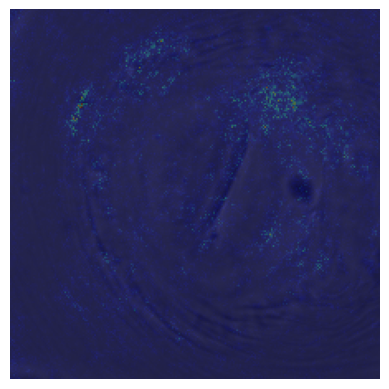

In [225]:
plt.imshow(ig_overlay)

plt.axis('off')

<Figure size 640x480 with 0 Axes>

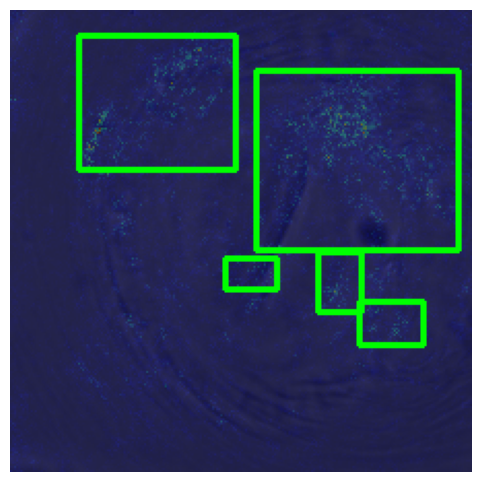

In [226]:

attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

# Convert to single importance map
ig_map = np.abs(attr).sum(axis=2)

# Normalize
ig_map = (ig_map - ig_map.min()) / (ig_map.max() - ig_map.min() + 1e-8)

# Select top 2% IG pixels
threshold = np.percentile(ig_map, 98)
binary_mask = (ig_map >= threshold).astype(np.uint8)


# threshold = 0.6
# binary_mask = (ig_map >= threshold).astype(np.uint8)
kernel = np.ones((9, 9), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_mask,
    connectivity=8
)

overlay_img = axes[2].images[-1].get_array().copy()
overlay_img = (overlay_img * 255).astype(np.uint8)


# boxed_overlay = ig_overlay.copy()

for i in range(1, num_labels):  # skip background
    x, y, w, h, area = stats[i]

    if area < 150:   # remove tiny noise boxes
        continue

    cv2.rectangle(
        overlay_img,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),  # green boxes
        2
    )

axes[2].images[-1].set_data(overlay_img / 255.0)
plt.draw()

plt.figure(figsize=(6,6))
plt.imshow(overlay_img)
plt.axis("off")
# plt.title("IG Overlay with Bounding Boxes")
plt.show()

In [227]:

# orig_img = np.array(test_img)   # PIL -> numpy (H0, W0, 3)
# H0, W0 = orig_img.shape[:2]

# # ===============================
# # 2. RECOMPUTE Resize(232) SHAPE
# # ===============================
# short_side = min(H0, W0)
# scale = 232 / short_side

# Hr = int(round(H0 * scale))
# Wr = int(round(W0 * scale))

# # ===============================
# # 3. CENTER CROP OFFSETS
# # ===============================
# crop_x = (Wr - 224) // 2
# crop_y = (Hr - 224) // 2

# # ===============================
# # 4. IG MAP → BINARY MASK (your logic)
# # ===============================
# attr = attributions_ig.squeeze().cpu().detach().numpy()
# attr = np.transpose(attr, (1, 2, 0))

# ig_map = np.abs(attr).sum(axis=2)
# ig_map = (ig_map - ig_map.min()) / (ig_map.max() - ig_map.min() + 1e-8)

# threshold = np.percentile(ig_map, 98)
# binary_mask = (ig_map >= threshold).astype(np.uint8)

# kernel = np.ones((9, 9), np.uint8)
# binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

# num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
#     binary_mask, connectivity=8
# )

# # ===============================
# # 5. DRAW BOXES ON ORIGINAL IMAGE
# # ===============================
# overlay = orig_img.copy()

# for i in range(1, num_labels):
#     x, y, w, h, area = stats[i]
#     if area < 150:
#         continue

#     # ---- Step 1: undo center crop ----
#     x_r = x + crop_x
#     y_r = y + crop_y
#     x2_r = x_r + w
#     y2_r = y_r + h

#     # ---- Step 2: undo resize ----
#     x1 = int(x_r * W0 / Wr)
#     y1 = int(y_r * H0 / Hr)
#     x2 = int(x2_r * W0 / Wr)
#     y2 = int(y2_r * H0 / Hr)

#     cv2.rectangle(
#         overlay,
#         (x1, y1),
#         (x2, y2),
#         (0, 255, 0),
#         3
#     )

# # ===============================
# # 6. DISPLAY
# # ===============================
# plt.figure(figsize=(7,7))
# plt.imshow(overlay)
# plt.axis("off")
# plt.title("IG Boxes Correctly Mapped to Original Image")
# plt.show()


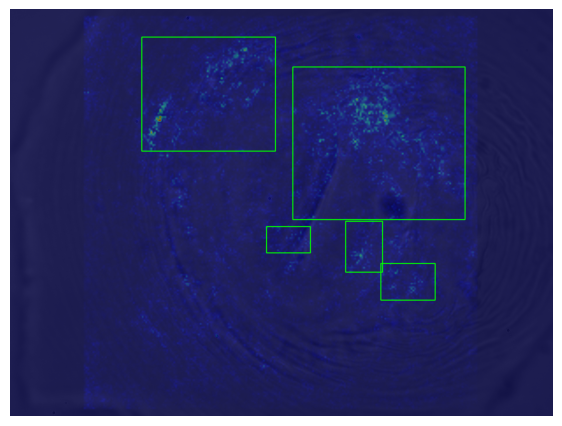

In [228]:

orig_img = np.array(test_img)  # PIL -> numpy
H0, W0 = orig_img.shape[:2]

# ======================================
# 2. RECOMPUTE Resize(232)
# ======================================
short_side = min(H0, W0)
scale = 232 / short_side
Hr = int(round(H0 * scale))
Wr = int(round(W0 * scale))

# CenterCrop offsets
crop_x = (Wr - 224) // 2
crop_y = (Hr - 224) // 2

# ======================================
# 3. IG ATTRIBUTION MAP (224×224)
# ======================================
attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

ig_map = np.abs(attr).sum(axis=2)
ig_map = (ig_map - ig_map.min()) / (ig_map.max() - ig_map.min() + 1e-8)

# ======================================
# 4. RESIZE IG MAP BACK TO RESIZED IMAGE
# ======================================
ig_resized = np.zeros((Hr, Wr), dtype=np.float32)
ig_resized[crop_y:crop_y+224, crop_x:crop_x+224] = ig_map

# Resize IG map to original image size
ig_original = cv2.resize(
    ig_resized, (W0, H0), interpolation=cv2.INTER_LINEAR
)

# ======================================
# 5. CREATE HEATMAP OVERLAY
# ======================================
heatmap = cv2.applyColorMap(
    np.uint8(255 * ig_original),
    cv2.COLORMAP_JET
)

heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

overlay = (
    0.6 * orig_img.astype(np.float32) +
    0.4 * heatmap.astype(np.float32)
).astype(np.uint8)

# ======================================
# 6. BOX EXTRACTION (ON IG MAP)
# ======================================
threshold = np.percentile(ig_map, 98)
binary_mask = (ig_map >= threshold).astype(np.uint8)

kernel = np.ones((9, 9), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_mask, connectivity=8
)

# ======================================
# 7. DRAW BOXES (MAPPED BACK)
# ======================================
for i in range(1, num_labels):
    x, y, w, h, area = stats[i]
    if area < 150:
        continue

    # undo center crop
    x_r = x + crop_x
    y_r = y + crop_y
    x2_r = x_r + w
    y2_r = y_r + h

    # undo resize
    x1 = int(x_r * W0 / Wr)
    y1 = int(y_r * H0 / Hr)
    x2 = int(x2_r * W0 / Wr)
    y2 = int(y2_r * H0 / Hr)

    cv2.rectangle(
        overlay,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        3
    )

# ======================================
# 8. DISPLAY FINAL RESULT
# ======================================
plt.figure(figsize=(7,7))
plt.imshow(overlay)
plt.axis("off")
# plt.title("IG Heatmap + Bounding Boxes (Correctly Mapped)")
plt.show()


In [229]:
attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))
axes[2].imshow(img)
axes[2].axis("off")
_ = viz.visualize_image_attr(
    attr,
    img,
    method='heat_map',
    sign='positive',
    cmap=default_cmap,
    alpha_overlay=0.6,          # transparency
    show_colorbar=True,
    plt_fig_axis=(fig, axes[2]),
    use_pyplot=False
)


In [230]:
# ---- IG attribution map ----
attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

# ---- Original image ----
axes[2].imshow(img)
axes[2].axis("off")

# ---- IG overlay ON TOP ----
_ = viz.visualize_image_attr(
    attr,
    img,
    method='heat_map',
    sign='positive',
    cmap=default_cmap,
    alpha_overlay=0.6,
    show_colorbar=True,
    plt_fig_axis=(fig, axes[2]),
    title="Integrated Gradients Overlay",
    use_pyplot=False
)


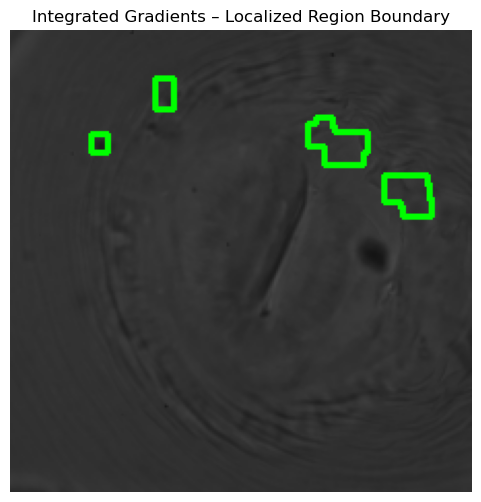

In [231]:
from captum.attr._utils.visualization import _normalize_attr
import cv2
# SAME attribution tensor you already used
attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))

# EXACT same processing as viz.visualize_image_attr
attr_norm = _normalize_attr(
    attr,
    sign='positive',
    outlier_perc=2,      # Captum default
    reduction_axis=2     # channel-wise reduction
)
# Threshold chosen to match visible IG localization
mask = (attr_norm > 0.55).astype(np.uint8)

# Fill gaps inside region
kernel = np.ones((9, 9), np.uint8)
mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)

# Remove small noisy islands
mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)

contours, _ = cv2.findContours(
    mask,
    cv2.RETR_EXTERNAL,      # outer boundary only
    cv2.CHAIN_APPROX_NONE   # smooth contour
)


img_boundary = (img * 255).astype(np.uint8).copy()

cv2.drawContours(
    img_boundary,
    contours,
    -1,
    (0, 255, 0),  # green
    2             # same thickness as example
)



plt.figure(figsize=(6,6))
plt.imshow(img_boundary)
plt.title("Integrated Gradients – Localized Region Boundary")
plt.axis("off")
plt.show()


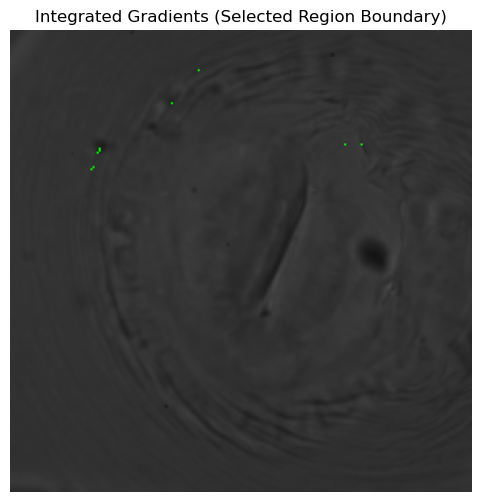

In [232]:
import cv2

# ==============================
# Boundary from SAME IG output
# ==============================


attr = attributions_ig.squeeze().cpu().detach().numpy()
attr = np.transpose(attr, (1, 2, 0))   # (H,W,C)

attr = np.maximum(attr, 0)

# 3. Collapse channels (this is what visualization does internally)
attr_map = np.sum(attr, axis=2)

# 4. Normalize (only for thresholding)
attr_map = (attr_map - attr_map.min()) / (attr_map.max() - attr_map.min() + 1e-8)

# 5. Threshold → selected region ONLY
binary_mask = (attr_map > 0.6).astype(np.uint8)  # 0.6 matches visible IG

# 6. Find boundary of selected region
contours, _ = cv2.findContours(
    binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
)

# 7. Draw boundary on ORIGINAL image
img_boundary = (img * 255).astype(np.uint8).copy()

cv2.drawContours(
    img_boundary,
    contours,
    -1,
    (0, 255, 0),  # GREEN boundary
    1             # thin boundary like your example
)

# ==============================
# Display FINAL result
# ==============================

plt.figure(figsize=(6,6))
plt.imshow(img_boundary)
plt.title("Integrated Gradients (Selected Region Boundary)")
plt.axis("off")
plt.show()


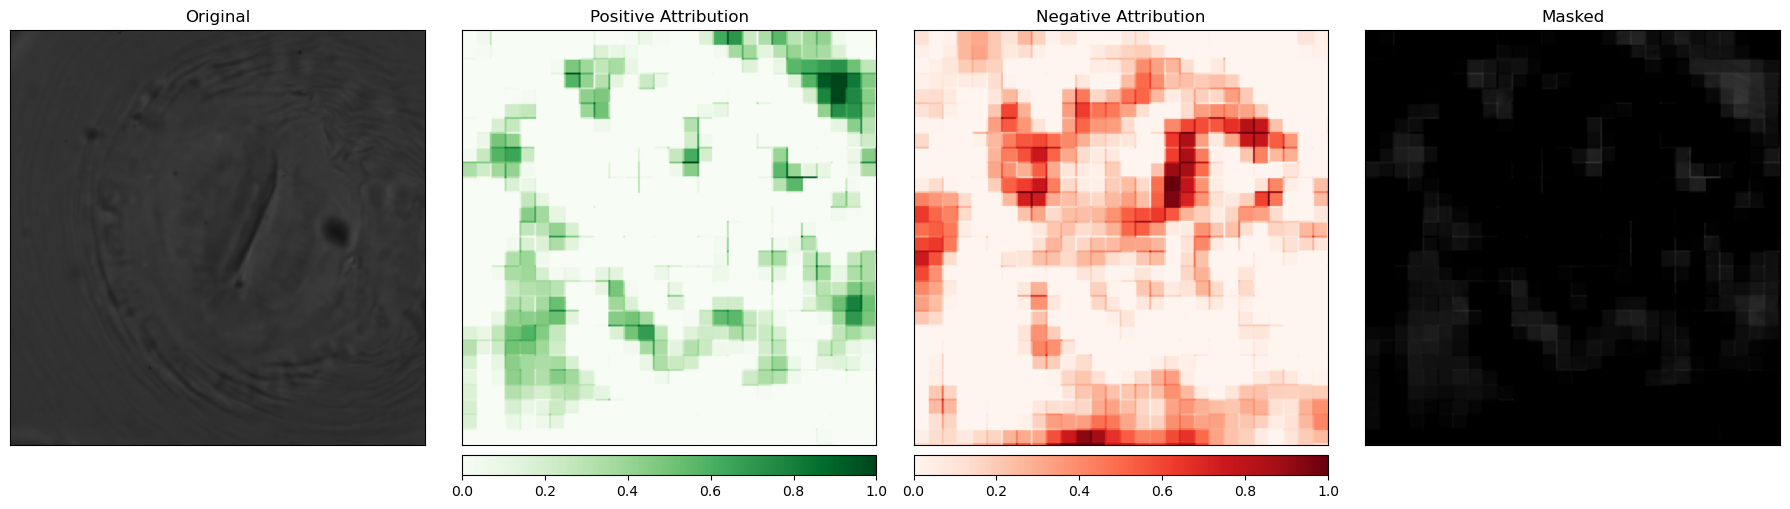

In [233]:
occlusion = Occlusion(model)

attributions_occ = occlusion.attribute(input_img,
                                       target=pred_class,
                                       strides=(3, 8, 8),
                                       sliding_window_shapes=(3,15, 15),
                                       baselines=0)


_ = viz.visualize_image_attr_multiple(np.transpose(attributions_occ.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      np.transpose(transformed_img.squeeze().cpu().detach().numpy(), (1,2,0)),
                                      ["original_image", "heat_map", "heat_map", "masked_image"],
                                      ["all", "positive", "negative", "positive"],
                                      show_colorbar=True,
                                      titles=["Original", "Positive Attribution", "Negative Attribution", "Masked"],
                                      fig_size=(18, 6)
                                     )

In [234]:
# imgs = ['/home/dbtproject/barsha/Image/test_set/Class0_Graminicola/Chaibasa_2_PP_7.tiff', 
#         '/home/dbtproject/barsha/Image/test_set/Class1_Incognita/Meloidogyne incognita_15.jpeg',
#           '/home/dbtproject/barsha/Image/test_set/Class2_Javanica/Meloidogyne javanica_12.tiff']

# for img in imgs:
#     img = Image.open(img)
#     transformed_img = transform(img)
#     input_img = transform_normalize(transformed_img)
#     input_img = input_img.unsqueeze(0).to(device) # the model requires a dummy batch dimension

#     output = model(input_img)
#     pred_class = output.argmax(dim=1).item()
#     print("Predicted class:", class_names[pred_class])
#     score = output[0, pred_class].item()
#     print('prediction Score:',score)